In [33]:
import numpy as np
import matplotlib.pyplot as plt

class Impedancia:
    def __init__(self, R, L, C, freq, tipo='serie'):
        self.R = R
        self.L = L
        self.C = C
        self.freq = np.array(freq)
        self.omega = 2 * np.pi * self.freq
        self.tipo = tipo.lower()
        if self.tipo not in ['serie', 'paralela']:
            raise ValueError("Tipo deve ser 'serie' ou 'paralela'.")

    def _Z_R(self):
        return self.R * np.ones_like(self.freq)

    def _Z_L(self):
        return 1j * self.omega * self.L

    def _Z_C(self):
        return 1 / (1j * self.omega * self.C)

    def Z_total(self):
        if self.tipo == 'serie':
            return self._Z_R() + self._Z_L() + self._Z_C()
        else:
            Y = 1 / self._Z_R() + 1 / self._Z_L() + 1 / self._Z_C()
            return 1 / Y

    def corrente_total(self, V):
        V = np.array(V)
        Z = self.Z_total()
        return V / Z

    def correntes_elementos(self, V):
        V = np.array(V)
        if self.tipo == 'serie':
            I = self.corrente_total(V)
            return {
                'IR': I,
                'IL': I,
                'IC': I
            }
        else:
            return {
                'IR': V / self._Z_R(),
                'IL': V / self._Z_L(),
                'IC': V / self._Z_C()
            }

    def tensoes_elementos(self, V):
        V = np.array(V)
        I = self.correntes_elementos(V)
        if self.tipo == 'serie':
            return {
                'VR': I['IR'] * self._Z_R(),
                'VL': I['IL'] * self._Z_L(),
                'VC': I['IC'] * self._Z_C()
            }
        else:
            return {
                'VR': V,
                'VL': V,
                'VC': V
            }

    def potencias_elementos(self, V):
        V = np.array(V)
        I = self.correntes_elementos(V)
        V_elem = self.tensoes_elementos(V)
        return {
            'PR': V_elem['VR'] * np.conj(I['IR']),
            'PL': V_elem['VL'] * np.conj(I['IL']),
            'PC': V_elem['VC'] * np.conj(I['IC'])
        }

    def _verificar_freq(self, outras):
        for z in outras:
            if not np.allclose(self.freq, z.freq):
                raise ValueError("Vetores de frequência incompatíveis.")

    def associar_serie(self, outras):
        if not isinstance(outras, list): outras = [outras]
        self._verificar_freq(outras)
        Z_total = self.Z_total()
        for z in outras:
            Z_total += z.Z_total()
        return Z_total

    def associar_paralelo(self, outras):
        if not isinstance(outras, list): outras = [outras]
        self._verificar_freq(outras)
        Y_total = 1 / self.Z_total()
        for z in outras:
            Y_total += 1 / z.Z_total()
        return 1 / Y_total

    def plot_impedancia_vs_frequencia(self):
        Z = self.Z_total()
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.plot(self.freq, np.abs(Z))
        plt.xlabel('Frequency (Hz)')
        plt.ylabel('|Z| (Ohms)')
        plt.title('Magnitude of Impedance')
        plt.grid(True)

        plt.subplot(1, 2, 2)
        plt.plot(self.freq, np.angle(Z, deg=True))
        plt.xlabel('Frequency (Hz)')
        plt.ylabel('Phase (degrees)')
        plt.title('Phase of Impedance')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    def plot_fasor_tensao_corrente(self, V, freq_fund):
        """
        Plot phasor diagram at the specified fundamental frequency.
        """
        V = np.array(V)
        idx = (np.abs(self.freq - freq_fund)).argmin()
        V0 = V[idx]
        I0 = self.corrente_total(V)[idx]

        plt.figure(figsize=(6, 6))
        plt.quiver(0, 0, np.real(V0), np.imag(V0), angles='xy', scale_units='xy', scale=1, color='blue', label='Voltage')
        plt.quiver(0, 0, np.real(I0), np.imag(I0), angles='xy', scale_units='xy', scale=1, color='red', label='Current')
        limite = 1.2 * max(abs(V0), abs(I0))
        plt.xlim(-limite, limite)
        plt.ylim(-limite, limite)
        plt.gca().set_aspect('equal')
        plt.grid(True)
        plt.title(f'Phasor Diagram (f = {self.freq[idx]:.1f} Hz)')
        plt.legend()
        plt.xlabel('Real')
        plt.ylabel('Imag')
        plt.show()




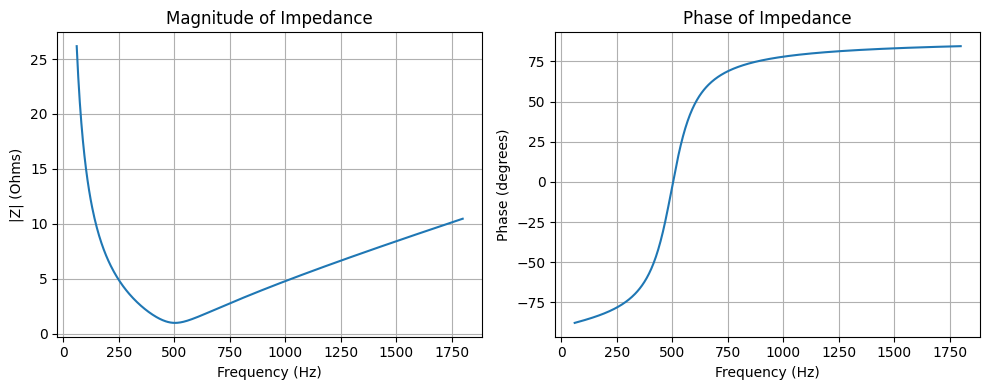

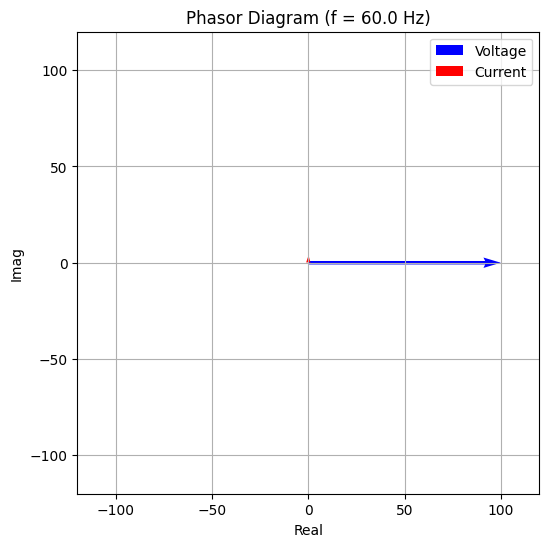

In [34]:
freq = np.linspace(60, 1800, 500)
z = Impedancia(R=1, L=1e-3, C=100e-6, freq=freq, tipo='serie')
V = 100 * np.ones_like(freq)

z.plot_impedancia_vs_frequencia()
z.plot_fasor_tensao_corrente(V, freq_fund=60)
